# Coverage Gaps and Under-Treatment
## State-level Coverage Gap Index for diabetes and cardiovascular medication in Medicare Part D

## Step 1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Colours for the charts
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#52514e"
plt.rcParams["font.family"] = "serif"

## Step 2: Load the four data files

In [2]:
drugs = pd.read_csv("MUP_DPR_RY26_P04_V10_DY24_Geo.csv", low_memory=False)
enrollment = pd.read_csv("Medicare_Monthly_Enrollment_Jul_2026.csv", encoding="utf-8-sig", thousands=",", na_values="*")
diabetes_prev = pd.read_csv("mmd_data_diabetes.csv")
ihd_prev = pd.read_csv("mmd_data_ihd.csv")

print("Drug file rows:", len(drugs))
drugs.head()

Drug file rows: 117661


,Prscrbr_Geo_Lvl,Prscrbr_Geo_Cd,Prscrbr_Geo_Desc,Brnd_Name,Gnrc_Name,Tot_Prscrbrs,Tot_Clms,Tot_30day_Fills,Tot_Drug_Cst,Tot_Benes,...,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes,LIS_Bene_Cst_Shr,NonLIS_Bene_Cst_Shr,Opioid_Drug_Flag,Opioid_LA_Drug_Flag,Antbtc_Drug_Flag,Antpsyct_Drug_Flag
0,National,NaN,National,1st Tier Unifine Pentips,"Pen Needle, Diabetic",209,378,695.6,10454.60,213.0,...,584.4,8336.36,NaN,174.0,140.44,3053.27,N,N,N,N
1,National,NaN,National,1st Tier Unifine Pentips Plus,"Pen Needle, Diabetic",442,965,1588.4,26074.56,451.0,...,1301.4,20918.75,NaN,360.0,686.07,5152.25,N,N,N,N
2,National,NaN,National,Abacavir,Abacavir Sulfate,2277,16298,21345.5,3054440.46,2349.0,...,14073.4,1994516.36,NaN,1491.0,6378.08,106462.22,N,N,N,N
3,National,NaN,National,Abacavir-Lamivudine,Abacavir Sulfate/Lamivudine,2162,17348,24469.2,5785643.94,2467.0,...,16985.9,3873672.58,NaN,1708.0,8498.40,266361.31,N,N,N,N
4,National,NaN,National,Abilify,Aripiprazole,1715,7131,9532.7,7066614.48,1478.0,...,3108.4,2038720.65,NaN,536.0,10911.96,119541.25,N,N,N,Y


## Step 3: Group the drugs (Table 5.3)
Each generic drug name is given a diabetes class or a cardiovascular class.
Insulin syringes, pens and pumps are excluded because they are not medicines.

In [3]:
def diabetes_class(name):
    name = name.lower()
    devices = ["pump", "pmp", "syringe", "syr,", "device", "supplies", "pen,reusable", "needle"]
    if any(word in name for word in devices) or "teduglutide" in name:
        return ""
    if "insulin" in name:
        return "Insulin"
    if any(word in name for word in ["glutide", "exenatide", "lixisenatide", "tirzepatide"]):
        return "GLP-1 receptor agonists"
    if "glifloz" in name:
        return "SGLT-2 inhibitors"
    if any(word in name for word in ["gliptin", "sitaglip", "linaglip"]):
        return "DPP-4 inhibitors"
    if "metformin" in name:
        return "Metformin"
    return ""

def cv_class(name):
    name = name.lower()
    if "statin" in name and "nystatin" not in name and "cilastatin" not in name:
        return "Statins"
    if "pril" in name and "prilocaine" not in name:
        return "ACE inhibitors"
    if "sartan" in name:
        return "ARBs"
    return ""

drugs["diabetes_class"] = drugs["Gnrc_Name"].apply(diabetes_class)
drugs["cv_class"] = drugs["Gnrc_Name"].apply(cv_class)

print("Diabetes drugs:", drugs.loc[drugs["diabetes_class"] != "", "Gnrc_Name"].nunique())
print("Cardiovascular drugs:", drugs.loc[drugs["cv_class"] != "", "Gnrc_Name"].nunique())

Diabetes drugs: 51
Cardiovascular drugs: 49


## Step 4: Keep the 50 states and DC

In [4]:
states = drugs[drugs["Prscrbr_Geo_Lvl"] == "State"].copy()
states = states[states["Prscrbr_Geo_Cd"].astype(str).str.isdigit()]       # removes Unknown / Foreign
states = states[states["Prscrbr_Geo_Cd"].astype(int) <= 56]               # removes territories
print("Number of states:", states["Prscrbr_Geo_Desc"].nunique())

Number of states: 51


## Step 5: Total 30-day fills by state

In [5]:
diabetes_fills = states[states["diabetes_class"] != ""].groupby("Prscrbr_Geo_Desc")["Tot_30day_Fills"].sum()
cv_fills = states[states["cv_class"] != ""].groupby("Prscrbr_Geo_Desc")["Tot_30day_Fills"].sum()

data = pd.DataFrame({"diabetes_fills": diabetes_fills, "cv_fills": cv_fills})
data.index = data.index.str.upper()

print("Total diabetes fills (million):", round(data["diabetes_fills"].sum() / 1e6, 1))
print("Total cardiovascular fills (million):", round(data["cv_fills"].sum() / 1e6, 1))

Total diabetes fills (million): 195.6
Total cardiovascular fills (million): 601.1


## Step 6: Add Part D beneficiaries and prevalence

In [6]:
enroll = enrollment[(enrollment["YEAR"] == 2024) & (enrollment["MONTH"] == "Year") & (enrollment["BENE_GEO_LVL"] == "State")]
enroll = enroll.set_index(enroll["BENE_STATE_DESC"].str.upper())
data["partd_benes"] = enroll["PRSCRPTN_DRUG_TOT_BENES"]

data["diabetes_prev"] = diabetes_prev.set_index("state")["analysis_value"]
data["ihd_prev"] = ihd_prev.set_index("state")["analysis_value"]

print("Missing values:", data.isna().sum().sum())
data.head()

Missing values: 0


,diabetes_fills,cv_fills,partd_benes,diabetes_prev,ihd_prev
Prscrbr_Geo_Desc,,,,,
ALABAMA,3481257.1,10040166.7,887786.0,29,25
ALASKA,238231.0,706835.7,80130.0,20,15
ARIZONA,3628197.5,12335715.2,1195253.0,22,20
ARKANSAS,1840949.2,5661171.1,534778.0,26,25
CALIFORNIA,21180788.2,61190115.6,5760268.0,27,19


## Step 7: Coverage Gap Index (ratio method and regression method)
* **Patients** = prevalence (%) × Part D beneficiaries
* **Fills per patient** = fills ÷ patients
* **Ratio method:** expected fills = patients × national average fills per patient; index = actual ÷ expected
* **Regression method (formula 6.2):** fills per patient = b0 + b1 × prevalence; index = actual ÷ predicted
* An index below **0.80** is flagged as a possible coverage gap

In [7]:
def coverage_gap(fills, prevalence):
    result = pd.DataFrame()
    result["prevalence"] = prevalence
    result["patients"] = prevalence / 100 * data["partd_benes"]
    result["fills"] = fills
    result["fills_per_patient"] = fills / result["patients"]

    # Ratio method
    national_rate = fills.sum() / result["patients"].sum()
    result["expected_fills"] = result["patients"] * national_rate
    result["ratio_index"] = result["fills"] / result["expected_fills"]
    result["shortfall"] = result["expected_fills"] - result["fills"]

    # Regression method
    reg = stats.linregress(result["prevalence"], result["fills_per_patient"])
    result["predicted"] = reg.intercept + reg.slope * result["prevalence"]
    result["regression_index"] = result["fills_per_patient"] / result["predicted"]

    # Comparison of the two methods
    rho, p_rho = stats.spearmanr(result["ratio_index"], result["regression_index"])
    low_ratio = set(result["ratio_index"].nsmallest(10).index)
    low_reg = set(result["regression_index"].nsmallest(10).index)

    print("Patients (million):", round(result["patients"].sum() / 1e6, 2))
    print("National average fills per patient:", round(national_rate, 2))
    print("Ratio index range:", round(result["ratio_index"].min(), 2), "to", round(result["ratio_index"].max(), 2))
    print("States below 1:", (result["ratio_index"] < 1).sum(),
          "| below 0.90:", (result["ratio_index"] < 0.9).sum(),
          "| below 0.80 (flagged):", (result["ratio_index"] < 0.8).sum())
    print("Regression slope:", round(reg.slope, 2), "| p-value:", "< 0.001" if reg.pvalue < 0.001 else round(reg.pvalue, 3), "| R-squared:", round(reg.rvalue**2, 2))
    print("Spearman correlation:", round(rho, 2))
    print("Overlap of ten lowest states:", len(low_ratio & low_reg), "of 10")

    return result.sort_values("ratio_index")

### Diabetes

In [8]:
diabetes = coverage_gap(data["diabetes_fills"], data["diabetes_prev"])

Patients (million): 13.82
National average fills per patient: 14.16
Ratio index range: 0.83 to 1.22
States below 1: 27 | below 0.90: 6 | below 0.80 (flagged): 0
Regression slope: -0.07 | p-value: 0.138 | R-squared: 0.04
Spearman correlation: 0.97
Overlap of ten lowest states: 9 of 10


**Table 7.2 – Ten states with the largest diabetes gaps (ratio method)**

In [9]:
diabetes[["prevalence", "patients", "fills_per_patient", "ratio_index", "regression_index", "shortfall"]].head(10).round(2)

,prevalence,patients,fills_per_patient,ratio_index,regression_index,shortfall
Prscrbr_Geo_Desc,,,,,,
DELAWARE,28,55329.68,11.80,0.83,0.84,130386.89
NEW MEXICO,24,86183.76,12.21,0.86,0.86,167341.87
MARYLAND,28,228767.84,12.42,0.88,0.89,396336.52
HAWAII,27,61985.52,12.54,0.89,0.89,100358.07
WYOMING,19,17408.75,12.72,0.90,0.87,25077.36
VERMONT,19,25001.72,12.74,0.90,0.87,35479.47
OKLAHOMA,28,168141.12,13.02,0.92,0.93,190264.24
NEW JERSEY,29,408092.64,13.16,0.93,0.95,404767.03
FLORIDA,26,1094547.22,13.20,0.93,0.93,1045278.89


### Cardiovascular disease

In [10]:
cardio = coverage_gap(data["cv_fills"], data["ihd_prev"])

Patients (million): 11.41
National average fills per patient: 52.69
Ratio index range: 0.8 to 1.57
States below 1: 18 | below 0.90: 9 | below 0.80 (flagged): 1
Regression slope: -1.97 | p-value: < 0.001 | R-squared: 0.72
Spearman correlation: 0.39
Overlap of ten lowest states: 4 of 10


**Table 7.3 – Ten states with the largest cardiovascular gaps (ratio method)**

In [11]:
cardio[["prevalence", "patients", "fills_per_patient", "ratio_index", "regression_index", "shortfall"]].head(10).round(2)

,prevalence,patients,fills_per_patient,ratio_index,regression_index,shortfall
Prscrbr_Geo_Desc,,,,,,
OKLAHOMA,25,150126.00,42.07,0.80,0.91,1593793.91
ARKANSAS,25,133694.50,42.34,0.80,0.92,1382753.39
FLORIDA,27,1136645.19,43.38,0.82,1.03,10579130.39
ALABAMA,25,221946.50,45.24,0.86,0.98,1653466.07
LOUISIANA,26,202614.88,45.27,0.86,1.02,1502338.45
MISSISSIPPI,24,121182.96,46.04,0.87,0.96,805880.40
NEW JERSEY,25,351804.00,46.08,0.87,1.00,2324027.72
DELAWARE,24,47425.44,47.17,0.90,0.98,261796.61
WEST VIRGINIA,24,83894.16,47.20,0.90,0.98,460657.69


**Table 7.4 – Ten states with the largest cardiovascular gaps (regression method)**

In [12]:
cardio.sort_values("regression_index")[["prevalence", "fills_per_patient", "predicted", "regression_index"]].head(10).round(2)

,prevalence,fills_per_patient,predicted,regression_index
Prscrbr_Geo_Desc,,,,
WYOMING,14,57.94,67.92,0.85
NEW MEXICO,15,56.93,65.95,0.86
VERMONT,15,57.75,65.95,0.88
ALASKA,15,58.81,65.95,0.89
OKLAHOMA,25,42.07,46.21,0.91
ARKANSAS,25,42.34,46.21,0.92
ARIZONA,20,51.60,56.08,0.92
MICHIGAN,22,49.12,52.13,0.94
MISSISSIPPI,24,46.04,48.18,0.96


### States among the ten lowest for both conditions

In [13]:
both = set(diabetes.index[:10]) & set(cardio.index[:10])
print(sorted(both))

['ARKANSAS', 'DELAWARE', 'FLORIDA', 'NEW JERSEY', 'OKLAHOMA']


## Step 8: Figures from Chapter 7

In [14]:
def scatter_plot(result, x_label, y_label, title):
    lowest = result.index[:10]
    colours = [ORANGE if state in lowest else BLUE for state in result.index]

    plt.figure(figsize=(8, 5))
    plt.scatter(result["prevalence"], result["fills_per_patient"], c=colours, edgecolors="white", s=50)

    # Regression line
    line = result.sort_values("prevalence")
    plt.plot(line["prevalence"], line["predicted"], color=GREY, label="Regression line")

    # Label the five lowest states
    for state in result.index[:5]:
        plt.annotate(state.title(), (result.loc[state, "prevalence"], result.loc[state, "fills_per_patient"]),
                     xytext=(5, 4), textcoords="offset points", fontsize=8)

    plt.scatter([], [], c=ORANGE, label="10 states with the lowest ratio index")
    plt.scatter([], [], c=BLUE, label="Other states")
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend(frameon=False)
    plt.grid(alpha=0.3)
    plt.show()


def index_plot(result, title):
    order = result.sort_values("ratio_index", ascending=False)
    colours = [ORANGE if state in result.index[:10] else BLUE for state in order.index]

    plt.figure(figsize=(8, 11))
    plt.hlines(order.index.str.title().str.replace(" Of ", " of "), 1, order["ratio_index"], color=colours, linewidth=2)
    plt.scatter(order["ratio_index"], order.index.str.title().str.replace(" Of ", " of "), c=colours, s=30)
    plt.axvline(1, color="black", linewidth=1, label="National average (1.0)")
    plt.axvline(0.8, color=GREY, linestyle="--", linewidth=1, label="Flag threshold (0.80)")
    plt.xlabel("Coverage Gap Index (ratio method)")
    plt.title(title)
    plt.legend(frameon=False, loc="center right")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

**Figure 7.2 – Diabetes prevalence and fills per patient**

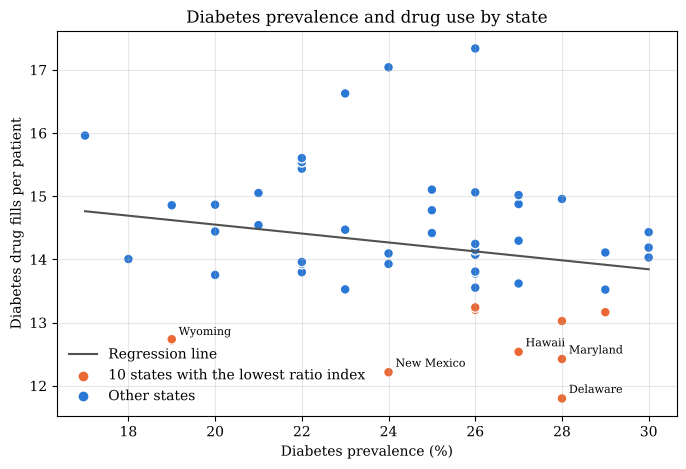

In [15]:
scatter_plot(diabetes, "Diabetes prevalence (%)", "Diabetes drug fills per patient",
             "Diabetes prevalence and drug use by state")

**Figure 7.3 – Coverage Gap Index for diabetes**

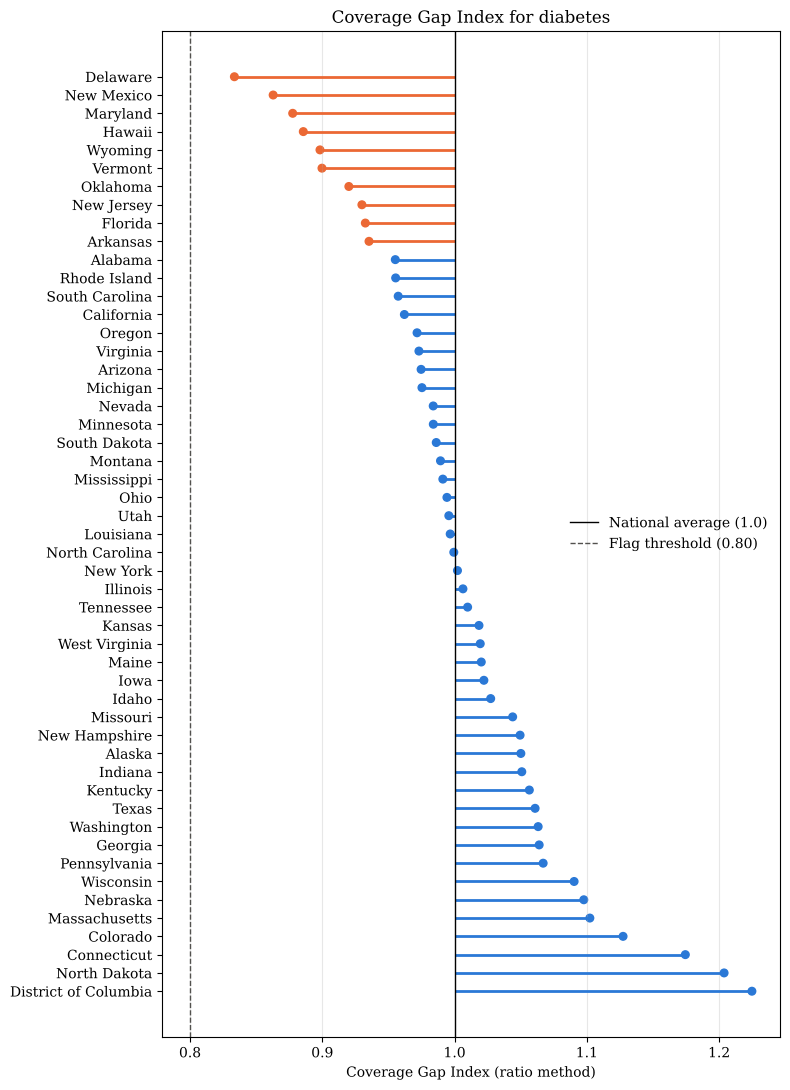

In [16]:
index_plot(diabetes, "Coverage Gap Index for diabetes")

**Figure 7.4 – Ischemic heart disease prevalence and fills per patient**

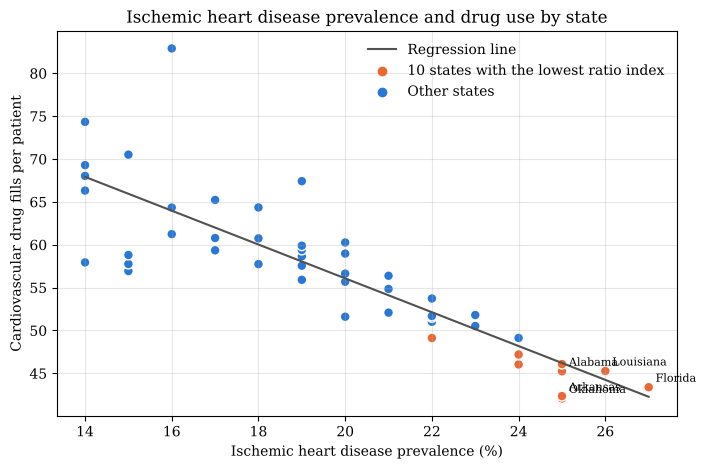

In [17]:
scatter_plot(cardio, "Ischemic heart disease prevalence (%)", "Cardiovascular drug fills per patient",
             "Ischemic heart disease prevalence and drug use by state")

**Figure 7.5 – Coverage Gap Index for cardiovascular disease**

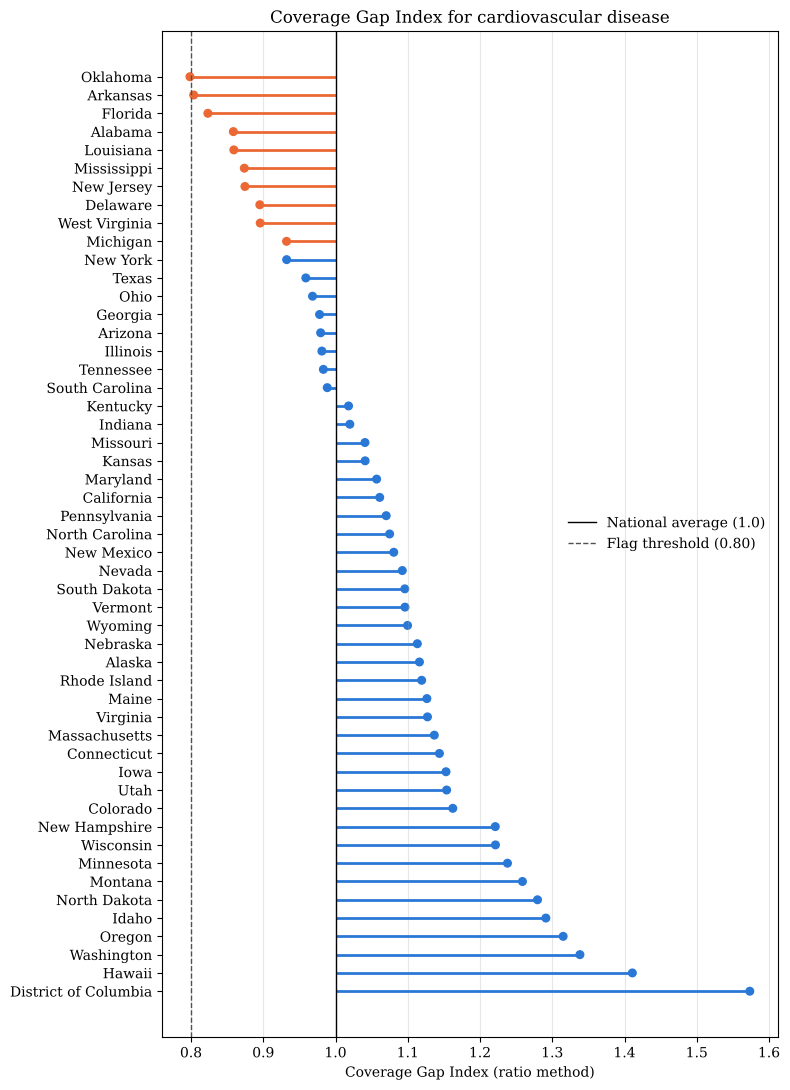

In [18]:
index_plot(cardio, "Coverage Gap Index for cardiovascular disease")

## Step 9: Extra figures
These three charts are Figures 7.1, 7.6 and 7.7 in Chapter 7.

**Figure 7.1 – Which drug classes make up the fills?**
Shows how the 2024 fills split across drug classes.

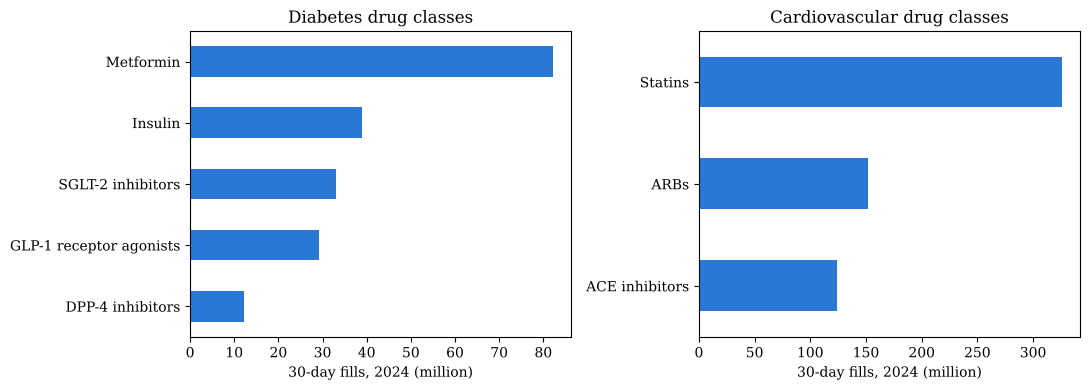

diabetes_class
DPP-4 inhibitors           12.1
GLP-1 receptor agonists    29.1
Insulin                    39.0
Metformin                  82.2
SGLT-2 inhibitors          33.1
Name: Tot_30day_Fills, dtype: float64
cv_class
ACE inhibitors    123.6
ARBs              151.6
Statins           325.8
Name: Tot_30day_Fills, dtype: float64


In [19]:
diabetes_by_class = states[states["diabetes_class"] != ""].groupby("diabetes_class")["Tot_30day_Fills"].sum() / 1e6
cv_by_class = states[states["cv_class"] != ""].groupby("cv_class")["Tot_30day_Fills"].sum() / 1e6

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
diabetes_by_class.sort_values().plot.barh(ax=axes[0], color=BLUE)
axes[0].set_title("Diabetes drug classes")
axes[0].set_xlabel("30-day fills, 2024 (million)")
axes[0].set_ylabel("")
cv_by_class.sort_values().plot.barh(ax=axes[1], color=BLUE)
axes[1].set_title("Cardiovascular drug classes")
axes[1].set_xlabel("30-day fills, 2024 (million)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

print((diabetes_by_class).round(1))
print((cv_by_class).round(1))

**Figure 7.6 – Do the two methods agree?**
Each dot is a state. Dots on the dashed line get the same score from both methods.
Diabetes dots sit close to the line (methods agree); cardiovascular dots are spread out (methods disagree).

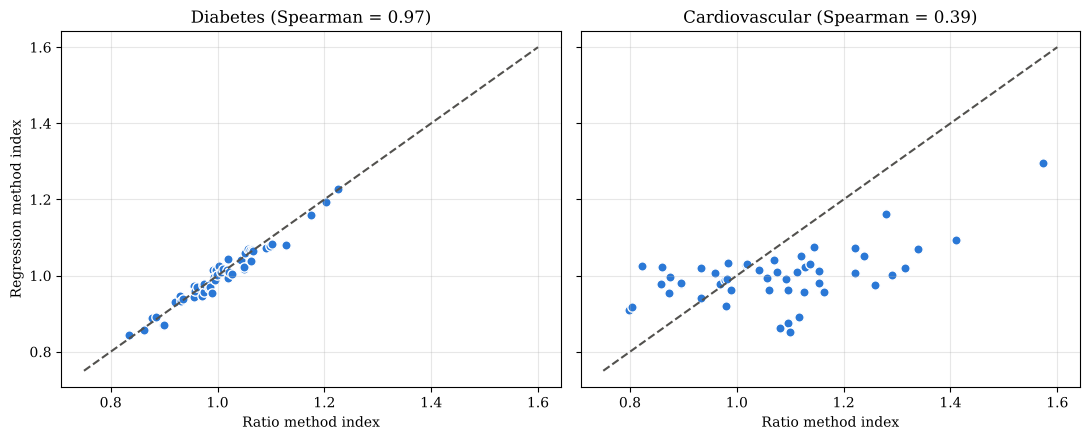

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, result, name in [(axes[0], diabetes, "Diabetes"), (axes[1], cardio, "Cardiovascular")]:
    rho = stats.spearmanr(result["ratio_index"], result["regression_index"])[0]
    ax.scatter(result["ratio_index"], result["regression_index"], color=BLUE, edgecolors="white", s=45)
    ax.plot([0.75, 1.6], [0.75, 1.6], color=GREY, linestyle="--")
    ax.set_title(f"{name} (Spearman = {rho:.2f})")
    ax.set_xlabel("Ratio method index")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Regression method index")
plt.tight_layout()
plt.show()

**Figure 7.7 – Where are the most prescriptions missing?**
Shortfall = expected fills − actual fills, for the ten states with the largest shortfall.
Large states such as Florida have the most missing fills even when their index is not the lowest.

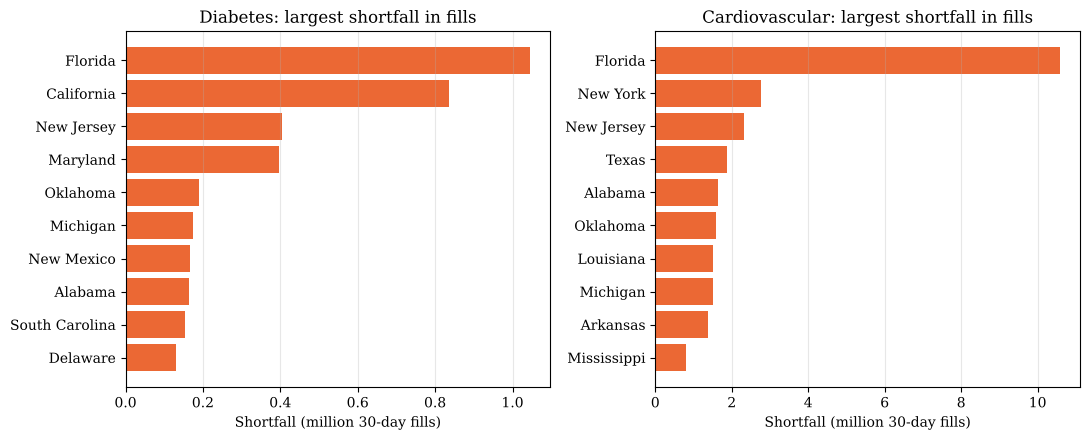

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, result, name in [(axes[0], diabetes, "Diabetes"), (axes[1], cardio, "Cardiovascular")]:
    top = (result["shortfall"] / 1e6).nlargest(10).sort_values()
    ax.barh(top.index.str.title(), top, color=ORANGE)
    ax.set_title(f"{name}: largest shortfall in fills")
    ax.set_xlabel("Shortfall (million 30-day fills)")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Step 10: Save the results

In [22]:
diabetes.round(3).to_csv("results_diabetes.csv")
cardio.round(3).to_csv("results_cardiovascular.csv")
print("Saved results_diabetes.csv and results_cardiovascular.csv")

Saved results_diabetes.csv and results_cardiovascular.csv
